# Iteration 2: adding DINO (patch v0.5.5, F3 and C2)

**Question.** The six maps of iteration 1 compare *where edges run* (edges, MIND, learned cells). DINO describes *what is there* ("roof", "road", "field"). Does adding it help the coarse search, and what does it take to put it into the fusion?

**What the patch asks for**
- **F3, dense DINO:** DINO patch tokens (not pooled), reduced by a PCA, resampled to the 4 x 4 pixel cell grid, correlated with the same masked ZNCC. A second score map over the whole disc.
- **The pooled DINO similarity** (the old "hint"): one vector per 224 px tile; cosine similarity as one more map.
- **C2, fusion:** normalise each map per photo (robust z-score), let a trained model weight them, instead of a hand-set `beta = 0.5`.
- **X6, test:** each map alone and fused, on the photos. Pass rule: fused beats edges + pooled prior (beta 0.5) by 0.03 in the low-altitude ceiling.

**How it is built (see `DESIGN.md`).** Every piece is a small block in `train/`: `features/dino_tokens.py`, `features/dino_dense.py`, `maps/dino_similarity.py`, `coarse_methods/`. This notebook only calls them and shows the result.

**One finding up front (Part 5):** dense DINO tokens sit on a 14 px grid, so the dense map is *not shift-invariant*. A query identical to a map window is found exactly; the same query shifted by a few pixels is not. Part 5 measures it.

---
# Part 1 · Settings

In [1]:
import os, sys, json, math, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not ((ROOT / "train").exists() and (ROOT / "src").exists()):
    ROOT = ROOT.parent                    # walk up to the repo folder
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

DATA = "official"        # "official" (d1 photos on small_sat_area, quick) or "nudt" (Changsha test photos)
N_PHOTOS = 60            # photos for the statistics
SEED = 7
CACHE = ROOT / "tests" / "Test_Iteration_2" / "results" / "cache"     # dense DINO map features are cached here (the slow part)

plt.rcParams["figure.dpi"] = 90
plt.rcParams["image.interpolation"] = "nearest"
print("repo:", ROOT.name, "| data:", DATA, "| photos:", N_PHOTOS)

repo: IdeaForge-GeoLoc-InterIIT15 | data: official | photos: 60


In [2]:
from train.datasets import photo_sets                  # first: it saves the development-set settings before NUDT changes them
from header import settings
from train import config
from train.features.dino_dense import DenseDinoFamily, fit_pca, sample_tokens
from train.features.dino_tokens import load_dino
from train.features.edge import EdgeFamily
from train.features.mind import MindFamily
from train.maps.dino_similarity import PooledDinoMap, add_pooled_map
from train.coarse_methods import build_methods, run_methods
from train.coarse_methods.inputs import make_inputs

from src.header.scoring import points_for_error
from src.image_processing.geometry import render_query
from src.image_processing.map_levels import level_gsd, map_piece
from src.image_processing.map_store import build_map_store
from src.coarse_search.search import pick_peaks

device = settings.DEVICE
print("running on:", device)


def show(axis, picture, title="", cmap="gray", vmin=0, vmax=1):
    axis.imshow(picture, cmap=cmap, vmin=vmin, vmax=vmax)
    axis.set_title(title, fontsize=9)
    axis.set_xticks([])
    axis.set_yticks([])

running on: cuda


---
# Part 2 · Photos, map and the existing feature families

The photos, the map store and the three families of iteration 1 (edges, MIND, learned), unchanged.

In [3]:
if DATA == "official":
    loaded = photo_sets.load_official_photos(N_PHOTOS, SEED)
else:
    loaded = photo_sets.load_nudt_photos(N_PHOTOS, SEED)
test_set, camera, satellite_map = loaded["test_set"], loaded["camera"], loaded["satellite_map"]
heights = np.array([item["rel_height"] for item in test_set.items])
print("%d photos, height %.0f to %.0f m, levels in use: %s" % (len(test_set.items), heights.min(), heights.max(), sorted(set(int(l) for l in test_set.query_levels))))

store = build_map_store(satellite_map)
level_images = store["levels"]

60 photos, height 100 to 350 m, levels in use: [3, 4, 5, 6, 7]


level 3: 0.85 m/pixel, picture 7812 x 4893, map coverage 70%
level 4: 1.20 m/pixel, picture 5524 x 3460, map coverage 70%
level 5: 1.70 m/pixel, picture 3906 x 2446, map coverage 70%
level 6: 2.40 m/pixel, picture 2762 x 1730, map coverage 70%
level 7: 3.39 m/pixel, picture 1953 x 1223, map coverage 70%


map store ready, took 13 s


In [4]:
families = {"edge": EdgeFamily(store), "mind": MindFamily(store, settings.LEVELS)}
f4_file = config.OUT_DIR / "models" / "f4.pt"
if f4_file.exists():
    from train.features.learned_family import LearnedFamily
    families["learned"] = LearnedFamily(store, settings.LEVELS, f4_file)
print("families:", list(families))

families: ['edge', 'mind', 'learned']


---
# Part 3 · DINO: the encoder, the PCA and the two DINO maps

- `load_dino()`: DINOv2 ViT-S/14, layer 8 (as `src/coarse_search/dino_hint.py`).
- `fit_pca`: 384 token channels to 8 (the pipeline is built for 8 channels; the patch suggests 16, and 8 for small GPUs). The PCA is fitted on tokens of random map windows.
- `DenseDinoFamily`: the token map of every level, built once and cached on disk. A family like the others: `query(canvas, valid)` and `map_features(level)`.
- `PooledDinoMap`: one vector per tile of the map, cosine similarity to the query.

In [5]:
start = time.time()
encoder = load_dino()
samples = sample_tokens({level: level_images[level] for level in settings.LEVELS[:2]}, encoder, windows_per_level=150, seed=SEED)
pca = fit_pca(samples, 8)
print("PCA on %d token vectors: the first 8 components keep %.0f %% of the variance (%.0f s)" % (len(samples), 100 * pca["explained"], time.time() - start))

start = time.time()
families["dino"] = DenseDinoFamily(level_images, settings.LEVELS, encoder, pca, cache_dir=CACHE)
print("dense DINO family ready, %.0f s (cached in %s)" % (time.time() - start, CACHE.relative_to(ROOT)))

start = time.time()
pooled = PooledDinoMap(level_images)
print("pooled DINO map ready, %.0f s" % (time.time() - start))

PCA on 76800 token vectors: the first 8 components keep 53 % of the variance (4 s)


dense DINO level 3: built, (8, 1223, 1953)


dense DINO level 4: built, (8, 865, 1381)


dense DINO level 5: built, (8, 611, 976)


dense DINO level 6: built, (8, 432, 690)
dense DINO level 7: built, (8, 305, 488)
dense DINO family ready, 3 s (cached in tests/Test_Iteration_2/results/cache)


level 3: 2104 tiles described, 3 s so far


level 4: 1042 tiles described, 5 s so far


level 5: 509 tiles described, 6 s so far


level 6: 254 tiles described, 6 s so far
level 7: 119 tiles described, 6 s so far
pooled DINO map ready, 7 s


---
# Part 4 · What DINO sees

For one photo: the north-up query, the true map tile, and the first three PCA channels of the dense DINO cells drawn as colours (one channel per colour). The edge-direction cells are shown for comparison. The two should group the same regions, but DINO groups by *kind of thing* (roofs, vegetation, road) and is much smoother (one token per 14 px, 3.5 cells).

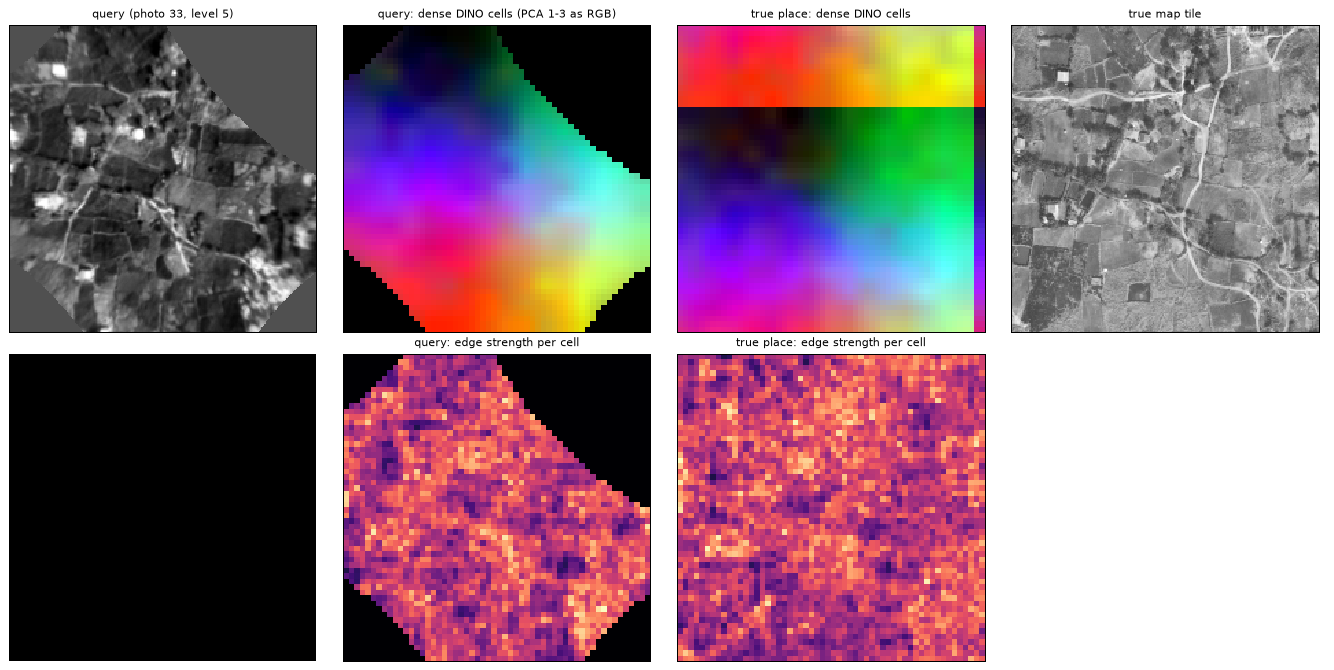

In [6]:
photo = int(np.argsort(heights)[len(heights) // 2])
level = int(test_set.query_levels[photo])
canvas, valid = render_query(test_set.items[photo], camera, level)
truth_x, truth_y = test_set.truths[photo]
true_tile = map_piece(level_images, level, truth_x, truth_y)


def cells_as_colours(cells):
    three = cells[:3].copy()
    for channel in range(3):
        low, high = np.percentile(three[channel], [2, 98])
        three[channel] = np.clip((three[channel] - low) / (high - low + 1e-6), 0, 1)
    return np.transpose(three, (1, 2, 0))


def map_cells_at(family, x_m, y_m, side=56):
    gsd = level_gsd(level)
    top = int(round(y_m / gsd / settings.CELL - side / 2))
    left = int(round(x_m / gsd / settings.CELL - side / 2))
    from src.coarse_search.search import cut_map_features
    return cut_map_features(family.map_features(level), top, left, side, side)


dino_query, dino_valid = families["dino"].query(canvas, valid)
dino_map = map_cells_at(families["dino"], truth_x, truth_y)
edge_query, edge_valid = families["edge"].query(canvas, valid)
edge_map = map_cells_at(families["edge"], truth_x, truth_y)

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
show(axes[0, 0], canvas, "query (photo %d, level %d)" % (photo, level))
show(axes[0, 1], cells_as_colours(dino_query) * dino_valid[..., None], "query: dense DINO cells (PCA 1-3 as RGB)")
show(axes[0, 2], cells_as_colours(dino_map), "true place: dense DINO cells")
show(axes[0, 3], true_tile, "true map tile")
show(axes[1, 0], np.zeros((8, 8)), "")
axes[1, 0].axis("off")
show(axes[1, 1], edge_query.sum(axis=0) * edge_valid, "query: edge strength per cell", cmap="magma", vmax=edge_query.sum(axis=0).max())
show(axes[1, 2], edge_map.sum(axis=0), "true place: edge strength per cell", cmap="magma", vmax=edge_map.sum(axis=0).max())
axes[1, 3].axis("off")
plt.tight_layout()
plt.show()

---
# Part 5 · The finding: dense DINO is not shift-invariant

Test with a crop of the **map itself** as the query, so a perfect method scores 1.0 at the true place.
- *aligned*: the crop is exactly one window of the DINO token grid of the map (positions that are multiples of 224 px).
- *shifted*: the same crop moved by (77, 51) pixels, which is what a real photo looks like to the map's token grid.

For each, the ZNCC score at the true place, the best score anywhere in the 5 km circle, and the distance of the best place from the truth. The edge family is run on the same crops as a reference.

In [7]:
def crop_test(family_name, name, spots):
    rows = []
    gsd = level_gsd(level)
    image = level_images[level]
    for top, left in spots:
        crop = (image[top:top + 224, left:left + 224] / 255.0).astype(np.float32)
        full = np.ones((224, 224), bool)
        truth = np.array([(left + 112) * gsd, (top + 112) * gsd])
        maps, geometry = __import__("train.maps.map_bank", fromlist=["x"]).compute_maps(crop, full, level, truth + np.array([300.0, -200.0]), {family_name: families[family_name]}, [name])
        score = maps[name]
        inside = geometry["inside"]
        peak = int(torch.argmax(torch.where(inside, score, torch.full_like(score, -9))))
        row, column = peak // score.shape[1], peak % score.shape[1]
        error = float(np.hypot(float(geometry["x_m"][column]) - truth[0], float(geometry["y_m"][row]) - truth[1]))
        at_row = int(torch.argmin((geometry["y_m"] - truth[1]).abs()))
        at_column = int(torch.argmin((geometry["x_m"] - truth[0]).abs()))
        rows.append((float(score[at_row, at_column]), float(score[inside].max()), error))
    return rows


rng = np.random.default_rng(SEED)
image = level_images[level]
aligned = []
while len(aligned) < 8:
    top = 224 * int(rng.integers(1, image.shape[0] // 224 - 2))
    left = 224 * int(rng.integers(1, image.shape[1] // 224 - 2))
    if (image[top:top + 224, left:left + 224] > 0).mean() > 0.95:
        aligned.append((top, left))
shifted = [(top + 77, left + 51) for top, left in aligned]

table = []
for family_name, name in [("edge", "edge_zncc"), ("dino", "dino_zncc")]:
    for label, spots in [("aligned", aligned), ("shifted", shifted)]:
        results = crop_test(family_name, name, spots)
        table.append({"map": name, "crop": label, "score at the true place (mean)": np.mean([r[0] for r in results]),
                      "best score anywhere (mean)": np.mean([r[1] for r in results]),
                      "found within 30 m": "%d of %d" % (sum(r[2] < 30 for r in results), len(results))})
display(pd.DataFrame(table).round(2))

,map,crop,score at the true place (mean),best score anywhere (mean),found within 30 m
0,edge_zncc,aligned,0.98,0.98,8 of 8
1,edge_zncc,shifted,0.75,0.75,8 of 8
2,dino_zncc,aligned,1.00,1.00,8 of 8
3,dino_zncc,shifted,-0.07,0.84,0 of 8


**How to read it.** The edge map finds the shifted crop as well as the aligned one (its cells do not depend on a fixed grid). The dense DINO map finds the aligned crop exactly, but for the shifted crop the score at the true place collapses while other places score much higher: the correlation latches onto the 14 px grid pattern. Averaging over shifted copies (`phases=` in `DenseDinoFamily`) and windows with margins did not cure it in our tests; a map per grid phase would, at about 49 times the cost. So the dense DINO map has to be judged on real photos (Part 7) before it is worth more work.

---
# Part 6 · The methods, one photo

Every map is a coarse method (`train/coarse_methods/`: one function per method, same inputs, one score map out). The pooled DINO map is not made by `compute_maps`; it is added through the `extra_maps` hook, then goes through the same z-scoring as the others.

Methods shown: `edge_zncc`, `learned_zncc`, `dino_zncc` (dense), `dino_pool` (pooled tile similarity), `edge_zncc + 0.5 * dino_pool` (the old hand-set blend) and `fused (6 maps)` (the iteration-1 model).

In [8]:
names = ["edge_zncc", "edge_cosine", "edge_mag", "edge_zncc_w", "mind_zncc"]
if "learned" in families:
    names.append("learned_zncc")
names += ["dino_zncc", "dino_pool"]
extra_names = ("dino_pool",)

fused_models = {}
state_file = config.OUT_DIR / "state.json"
if state_file.exists():
    from coarse_search.fusion import load_model
    best = json.load(open(state_file))["results"]["fusion_best"]
    model = load_model(config.OUT_DIR / "models" / "fusion" / (best["tag"] + ".pt")).to(device).eval()
    fused_models["fused (6 maps)"] = (model, best["subset"])

methods = build_methods(["edge_zncc", "mind_zncc", "learned_zncc", "dino_zncc", "dino_pool"],
                        fused_models=fused_models, hints=[("edge_zncc", "dino_pool", 0.5)])
methods = {label: method for label, method in methods.items() if label != "learned_zncc" or "learned" in families}
print("methods:", list(methods))


def add_pool(maps, geometry, canvas, valid, level, prior_m):
    add_pooled_map(maps, pooled, canvas, valid, level, prior_m, geometry)


def inputs_for(photo_index):
    item = test_set.items[photo_index]
    level = int(test_set.query_levels[photo_index])
    canvas, valid = render_query(item, camera, level)
    inputs = make_inputs(canvas, valid, level, test_set.priors[photo_index], families, names, extra_maps=add_pool, extra_names=extra_names)
    return canvas, valid, level, inputs


def peak_errors_in_sigma(peaks, photo_index):
    truth = test_set.truths[photo_index]
    errors = []
    for row in peaks:
        if row[1] < 1e8:
            errors.append(math.hypot(row[1] - truth[0], row[2] - truth[1]) / test_set.sigmas[photo_index])
    if len(errors) == 0:
        errors.append(1e9)
    return errors

methods: ['edge_zncc', 'mind_zncc', 'learned_zncc', 'dino_zncc', 'dino_pool', 'fused (6 maps)', 'edge_zncc + 0.5 * dino_pool']


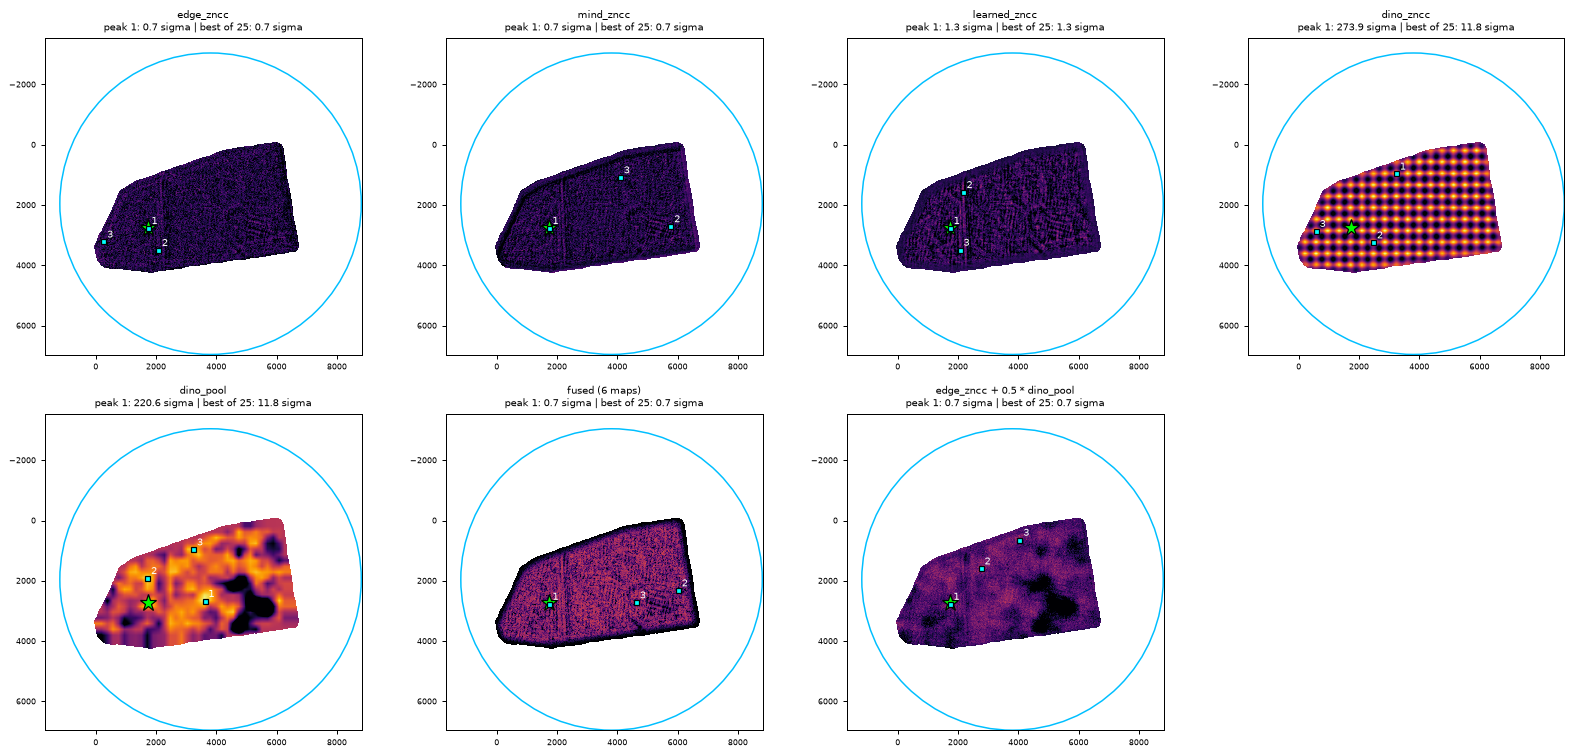

,peak 1 error (sigma),best of 25 (sigma),share of positions below the true place
method,,,
edge_zncc,0.7,0.7,1.0000
mind_zncc,0.7,0.7,1.0000
learned_zncc,1.3,1.3,1.0000
dino_zncc,273.9,11.8,0.7887
dino_pool,220.6,11.8,0.9500
fused (6 maps),0.7,0.7,1.0000
edge_zncc + 0.5 * dino_pool,0.7,0.7,1.0000


In [9]:
def draw_heat_map(axis, score_map, geometry, photo_index, peaks, title):
    heat = score_map.cpu().numpy().copy()
    inside = geometry["inside"].cpu().numpy()
    heat[~inside | (heat <= -1)] = np.nan
    x_m = geometry["x_m"].cpu().numpy()
    y_m = geometry["y_m"].cpu().numpy()
    low = np.nanpercentile(heat, 5)
    axis.imshow(heat, cmap="inferno", vmin=low, vmax=np.nanmax(heat), extent=(x_m[0], x_m[-1], y_m[-1], y_m[0]))
    axis.add_patch(plt.Circle(test_set.priors[photo_index], settings.DISC_RADIUS, fill=False, color="deepskyblue", lw=1.2))
    axis.plot(*test_set.truths[photo_index], "*", color="lime", markersize=14, markeredgecolor="black")
    for rank in range(3):
        if peaks[rank, 1] < 1e8:
            axis.plot(peaks[rank, 1], peaks[rank, 2], "s", color="cyan", markersize=4, markeredgecolor="black")
            axis.annotate(str(rank + 1), (peaks[rank, 1], peaks[rank, 2]), color="white", fontsize=8, xytext=(3, 3), textcoords="offset points")
    axis.set_title(title, fontsize=8)
    axis.tick_params(labelsize=6)


canvas, valid, level, inputs = inputs_for(photo)
scores = run_methods(methods, inputs)
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
axes = axes.ravel()
rows = []
for slot, (label, score) in enumerate(scores.items()):
    peaks = pick_peaks(score, inputs["geometry"])
    errors = peak_errors_in_sigma(peaks, photo)
    values = score[inputs["usable"]]
    at_row = int(torch.argmin((inputs["geometry"]["y_m"] - test_set.truths[photo][1]).abs()))
    at_column = int(torch.argmin((inputs["geometry"]["x_m"] - test_set.truths[photo][0]).abs()))
    rows.append({"method": label, "peak 1 error (sigma)": round(errors[0], 1), "best of 25 (sigma)": round(min(errors), 1),
                 "share of positions below the true place": round(float((values < score[at_row, at_column]).float().mean()), 4)})
    draw_heat_map(axes[slot], score, inputs["geometry"], photo, peaks, "%s\npeak 1: %.1f sigma | best of 25: %.1f sigma" % (label, errors[0], min(errors)))
for slot in range(len(scores), 8):
    axes[slot].axis("off")
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).set_index("method"))

---
# Part 7 · The methods over the photos (coarse stage only)

For each photo all maps are made once and every method takes its 25 peaks. `top-1` is how often the first peak is within k sigma of the truth; `ceiling` is how often the right place is anywhere in the 25 (what the fine stage can use). The patch's pass rule looks at the ceiling for low photos (height up to 200 m).

In [10]:
record = {label: {"top1": [], "best25": []} for label in methods}
failed = []
start = time.time()
for index in range(len(test_set.items)):
    try:
        canvas_now, valid_now, level_now, inputs_now = inputs_for(index)
        scores_now = run_methods(methods, inputs_now)
        found = {}
        for label, score in scores_now.items():
            errors = peak_errors_in_sigma(pick_peaks(score, inputs_now["geometry"]), index)
            found[label] = (errors[0], min(errors))
    except Exception as error:
        print("photo %d failed: %s: %s" % (index, type(error).__name__, str(error)[:120]))
        failed.append(index)
        continue
    for label, (first, best) in found.items():
        record[label]["top1"].append(first)
        record[label]["best25"].append(best)
    if device == "cuda":
        torch.cuda.empty_cache()
    if index % 10 == 0:
        print("photo %d of %d, %.0f s" % (index + 1, len(test_set.items), time.time() - start))
done = [i for i in range(len(test_set.items)) if i not in failed]
low = np.array([heights[i] <= 200 for i in done])
print("done: %d photos (%d failed), %d low and %d high" % (len(done), len(failed), low.sum(), (~low).sum()))

photo 1 of 60, 1 s


photo 11 of 60, 7 s


photo 21 of 60, 14 s


photo 31 of 60, 21 s


photo 41 of 60, 27 s


photo 51 of 60, 36 s


done: 60 photos (0 failed), 30 low and 30 high


,top-1 <= 1 sigma,top-1 <= 4 sigma,ceiling <= 4 sigma,"ceiling, low photos","ceiling, high photos"
method,,,,,
edge_zncc,0.533,0.833,0.917,0.867,0.967
mind_zncc,0.533,0.850,0.950,0.900,1.000
learned_zncc,0.517,0.883,0.967,0.933,1.000
dino_zncc,0.000,0.000,0.033,0.067,0.000
dino_pool,0.000,0.000,0.033,0.067,0.000
fused (6 maps),0.600,0.917,0.983,0.967,1.000
edge_zncc + 0.5 * dino_pool,0.533,0.850,0.933,0.900,0.967


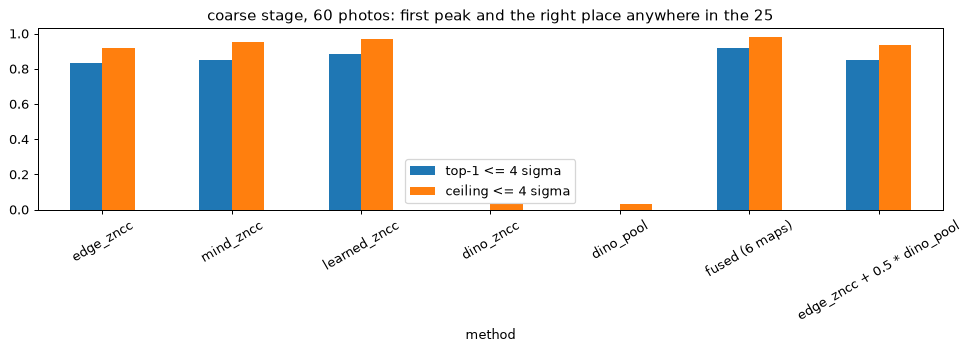

In [11]:
rows = []
for label, values in record.items():
    top1 = np.array(values["top1"])
    best25 = np.array(values["best25"])
    row = {"method": label, "top-1 <= 1 sigma": (top1 <= 1).mean(), "top-1 <= 4 sigma": (top1 <= 4).mean(), "ceiling <= 4 sigma": (best25 <= 4).mean()}
    if low.sum() > 0:
        row["ceiling, low photos"] = (best25[low] <= 4).mean()
    if (~low).sum() > 0:
        row["ceiling, high photos"] = (best25[~low] <= 4).mean()
    rows.append(row)
coarse_table = pd.DataFrame(rows).set_index("method")
display(coarse_table.round(3))

fig, axis = plt.subplots(figsize=(11, 4))
coarse_table[["top-1 <= 4 sigma", "ceiling <= 4 sigma"]].plot.bar(ax=axis, rot=30)
axis.set_title("coarse stage, %d photos: first peak and the right place anywhere in the 25" % len(done))
plt.tight_layout()
plt.show()

---
# Part 8 · How DINO plugs into the fusion (C2)

The fusion model weighs the maps it is given. To include DINO it must be trained on candidate sets that have the DINO maps in them. `dump_split` (the block that writes candidate sets) got one hook for this: `extra_maps(maps, geometry, canvas, valid, level, prior)` adds maps that `compute_maps` cannot make, and `extra_names` says which names those are. Nothing else changes: `run_ablation` and `load_shards` work on any list of names.

Below, a small dump of the photos of this notebook as a plumbing check (the shapes, not the accuracy: a real fusion needs thousands of training photos, see the README).

In [12]:
from train.datasets.candidates import dump_split, load_shards

demo_folder = ROOT / "tests" / "Test_Iteration_2" / "results" / "demo_shards"
config.SHARD_SIZE = 10
demo_ids = np.arange(min(20, len(test_set.items)))
dump_split(test_set, store, families, names, demo_ids, demo_folder, "demo", log=lambda *a: None, extra_maps=add_pool, extra_names=extra_names)
demo = load_shards(demo_folder, "demo", names)
print("candidate sets: z is %s = (photos, candidates per photo, maps)" % (tuple(demo["z"].shape),))
print("maps in the order of z:", names)
print("context has %d numbers per photo (2 per map + the ground pixel size)" % demo["context"].shape[1])

candidate sets: z is (20, 79, 8) = (photos, candidates per photo, maps)
maps in the order of z: ['edge_zncc', 'edge_cosine', 'edge_mag', 'edge_zncc_w', 'mind_zncc', 'learned_zncc', 'dino_zncc', 'dino_pool']
context has 17 numbers per photo (2 per map + the ground pixel size)


In [13]:
# the same shards go straight into the existing ablation (a handful of photos: this only proves that it runs)
from train.models.fusion_ablation import run_ablation

config.FUSION_EPOCHS = 60
config.BOOTSTRAP = 100
half = len(demo["z"]) // 2
part = lambda data, a, b: dict(z=data["z"][a:b], context=data["context"][a:b], groups=data["groups"][a:b], kind=data["kind"][a:b])
rows_demo, best_demo = run_ablation(part(demo, 0, half), part(demo, half, len(demo["z"])), names, ROOT / "tests" / "Test_Iteration_2" / "results" / "demo_models", log=lambda *a: None)
print("trained %d fusion models on the extra maps; best subset: %s (%s)" % (len(rows_demo), best_demo["maps"], best_demo["kind"]))

trained 20 fusion models on the extra maps; best subset: edge_zncc+edge_cosine+edge_mag (linear)


**Next (see the README of Test_Iteration_2).**
1. Judge the dense DINO map on the full set of photos (500 official, NUDT test) with these cells; the finding in Part 5 predicts it is weak.
2. If the pooled map or the dense map adds something, dump real training candidate sets (3000 NUDT train + valid photos, about 20 minutes) with `extra_maps`, retrain the fusion with and without DINO and compare on real photos (paired bootstrap).
3. If dense DINO stays weak: a phase-exact map, or leave dense DINO out and keep only the pooled map (cheap, shift-free).
4. Check whether pseudo-thermal photos (iteration 1) help the DINO fusion.